In [1]:
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

In [2]:
from typing import Dict, List, Union, Optional
from pathlib import Path

def get_classification_TTA_paths(
    source: str,
    target: str,
    modelname: str,
    foldernames: Dict[str, str],
    augs: List[str],
    selected_augs: Optional[Dict[str, List[int]]] = None,
    base_folder: Union[str, Path] = Path(
        "/g/kreshuk/talks/domain_gap/experiments/patch_classification"
    ),
):
    # check if base_folder is a string
    if isinstance(base_folder, str):
        base_folder = Path(base_folder)

    pred_folder = base_folder / Path(
        f"{source}_to_{target}/consistency/predictions/{modelname}"
    )
    # check if the folder exists
    if not pred_folder.exists():
        raise FileNotFoundError(f"Folder {pred_folder} does not exist.")

    paths: Dict[str, List[Path]] = {}
    for aug in augs:
        folder_path = pred_folder / foldernames[aug]
        # check if the folder exists
        if not folder_path.exists():
            raise FileNotFoundError(f"Folder {folder_path} does not exist.")
        aug_paths = list(
            folder_path.glob(f"{source[0].upper()}to{target[0].upper()}_{aug}*.npz")
        )
        if selected_augs:
            aug_paths = [aug_paths[i] for i in selected_augs[aug]]

        paths[aug] = aug_paths
    return paths

In [3]:
def classification_TTA_predictions(
    source: str,
    target: str,
    modelname: str,
    foldernames: Dict[str, str],
    augs: List[str],
    selected_augs: Dict[str, List[int]] = None,
):
    predictions = []
    soft_predictions = []
    gt_labels = []
    f1_scores = []
    aug_params = []

    paths = get_classification_TTA_paths(
        source=source,
        target=target,
        modelname=modelname,
        foldernames=foldernames,
        augs=augs,
        selected_augs=selected_augs,
    )
    for aug in augs:
        for path in paths[aug]:
            with np.load(path, "r") as data:
                predictions.append(data["predictions"])
                soft_predictions.append(data["soft_predictions"])
                gt_labels.append(data["labels"])
                f1_scores.append(data["f1_score"])
                if "aug_params" in data:
                    aug_params.append(data["aug_params"])
    preds = np.vstack(predictions)
    soft_preds = np.vstack(soft_predictions)
    labels = np.vstack(gt_labels)
    f1s = np.vstack(f1_scores)
    if len(aug_params) > 0:
        aug_params = np.vstack(aug_params)

    return preds, soft_preds, labels, f1s, aug_params

In [4]:
from numpy.typing import NDArray
from typing import Any

def calculate_EI_binary(
    preds: NDArray[Any],
    soft_preds: NDArray[Any],
):
    # remove single dimensions
    # preds = np.squeeze(preds)
    # soft_preds = np.squeeze(soft_preds)
    # mask for change in classification prediction relative to No Aug
    mask_same_pred = preds[1:] == preds[0]
    mask0 = preds[1:] == 0
    mask1 = preds[1:] == 1
    mask0 = np.logical_and(mask0, mask_same_pred)
    mask1 = np.logical_and(mask1, mask_same_pred)
    EI_result = np.zeros_like(soft_preds[1:])
    zero_inverted_None_pred = np.where(preds[0] == 0, 1 - soft_preds[0], soft_preds[0])
    EI_result[mask1] = soft_preds[1:][mask1]
    EI_result[mask0] = 1 - soft_preds[1:][mask0]
    EI_result = np.sqrt(zero_inverted_None_pred[np.newaxis, :] * EI_result)
    return EI_result, EI_result.mean(axis=1), mask0, mask1

In [5]:
def plot_combined_selected_augs_metric_vs_F1(
    metric_scores,
    F1_scores,
    metric_name,
    target_datasets,
    source_datasets,
    augmentations,
    alphas_selected,
    xlim=(0.6, 1),
    ylim=(0.5, 1),
    figsize=(25, 15),
    point_size=100,
    fontsize=25,
    legend_size=30,
    n_rows=2,
    n_cols=2,
    colors=["#377eb8", "#ff7f00", "#2ca02c"],
    markers=None,
    marker_by_source=None,
    subplot_titles=None,
    x_label=None,
    y_label=None,
    save_path=None,
    title_ending="",
):
    fig, axs = plt.subplots(n_rows, n_cols, figsize=figsize)
    axs = axs.ravel()

    # Define a ListedColormap for red, green, and blue
    cmap = mcolors.ListedColormap(colors)

    for i, target in enumerate(target_datasets):
        transfer_types = []
        for j, source in enumerate(source_datasets):
            transfer = f"{source[0].upper()}to{target[0].upper()}"
            transfer_types.append(transfer)
            marker = (markers or {}).get(
                transfer, (marker_by_source or {}).get(source, "o")
            )
            metric_transfer = []
            F1_transfer = []
            for k, aug in enumerate(augmentations):
                F1s = F1_scores[aug, transfer][0, 0]
                metric = metric_scores[aug, transfer][alphas_selected[aug]]
                metric_transfer.append(metric)
                F1_transfer.append(F1s)
            axs[i].scatter(
                np.mean(np.concatenate(metric_transfer)),
                F1_transfer[0],
                color=cmap(j),
                marker=marker,
                s=point_size,
            )
        for t, transfer in enumerate(transfer_types):
            source = source_datasets[t]
            marker = (markers or {}).get(
                transfer, (marker_by_source or {}).get(source, "o")
            )
            axs[i].scatter(
                [],
                [],
                color=cmap(t),
                marker=marker,
                label=transfer,
            )
        lgnd = axs[i].legend(loc="upper left", prop={"size": legend_size})
        for t in range(len(transfer_types)):
            lgnd.legend_handles[t]._sizes = [point_size]
        axs[i].set_title(
            (subplot_titles or {}).get(
                target, f"To {target} \n{metric_name} vs F1{title_ending}"
            ),
            fontsize=fontsize + 5,
        )
        axs[i].set_xlabel(x_label or metric_name, fontsize=fontsize)
        axs[i].set_ylabel(y_label or "F1 score (No aug)", fontsize=fontsize)
        axs[i].tick_params(
            axis="both", which="major", labelsize=fontsize, pad=10
        )
        # axs[i].plot(xlim, ylim, "--", color="black", alpha=0.5)
        axs[i].grid()
        axs[i].set_xlim(xlim)
        axs[i].set_ylim(ylim)

    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, format="svg", pad_inches=0)
    plt.show()

In [6]:
source_datasets = ['epfl', 'Hmito', 'Rmito']
target_datasets = ['epfl', 'Hmito', 'Rmito', 'VNC']
augmentations = ['Brt', 'Ctr', 'Gamma', 'Gauss']
sweep_folders = {
    'None': 'aug_sweep',
    'Brt': 'aug_sweep',
    'Ctr': 'aug_sweep2',
    'Gamma': 'aug_sweep2',
    'Gauss': 'aug_sweep',
}
sweep_folders_Hmito = {
    'None': 'aug_sweep',
    'Brt': 'aug_sweep',
    'Ctr': 'aug_sweep',
    'Gamma': 'aug_sweep',
    'Gauss': 'aug_sweep',
}
source_models = {
    'epfl': 'RN18_epfl80_aug5_soft', 
    'Hmito': 'RN18_Hmito80_aug2_soft', 
    'Rmito': 'RN18_Rmito80_aug3_soft'
}
aug_markers = {'Brt': 'o', 'Ctr': 's', 'Gamma': 'D', 'Gauss': '^'}

In [7]:
EI_scores = {}
F1_scores = {}
Aug_parameters = {}
for aug in tqdm(augmentations):
    for target in target_datasets:
        #HD_scores = []
        #F1_scores = []
        #transfers = []
        for source in source_datasets:
            transfer = f"{source[0].upper()}to{target[0].upper()}"
            #transfers.append(transfer)
            if source == 'Hmito':
                folders = sweep_folders_Hmito
            else:
                folders = sweep_folders

            preds, soft_preds, gt, f1, aug_params = classification_TTA_predictions(
                source, target, modelname=source_models[source], foldernames=folders, augs=["None", aug]
            )
            EInvariance, EI_mean, mask0, mask1 = calculate_EI_binary(
                preds, soft_preds
            )
            #HD_scores.append(1-aug_HDs)
            #F1_scores.append(f1)
            EI_scores[aug, transfer] = EI_mean
            F1_scores[aug, transfer] = f1
            Aug_parameters[aug, transfer] = aug_params

  0%|          | 0/4 [00:00<?, ?it/s]

100%|██████████| 4/4 [00:00<00:00,  6.25it/s]


In [8]:
# Brt:          Ctr:
# *[0.1, 0.2]    [0.1, 0.2]  *[1.6, 1.8]  [2.8, 3.0]  
# *[0.2, 0.4]    [0.2, 0.4]  *[1.8, 2.0]
# [0.4, 0.6]    *[0.4, 0.6]  *[2.0, 2.2]
# [0.6, 0.8]    *[0.6, 0.8]  [2.2, 2.4]
# [0.8, 1.0]    *[0.8, 1.0]  [2.4, 2.6]
#               *[1.0, 1.6]  [2.6, 2.8]
#                   
# Gamma:                     Gauss:                  
# [0.1, 0.2]  *[1.0, 1.5]     *[0.1, 0.2]
# [0.2, 0.4]  [1.5, 2.0]     *[0.2, 0.4]        
# *[0.4, 0.6]  [2.0, 2.5]     [0.4, 0.6]
# *[0.6, 0.8]  [2.5, 3.0]     [0.6, 0.8]
# *[0.8, 1.0]
#
selected_alphas = {
    "Brt": np.r_[:2],
    "Ctr": np.r_[2:9],
    "Gamma": np.r_[2:6],
    "Gauss": np.r_[:2]
}

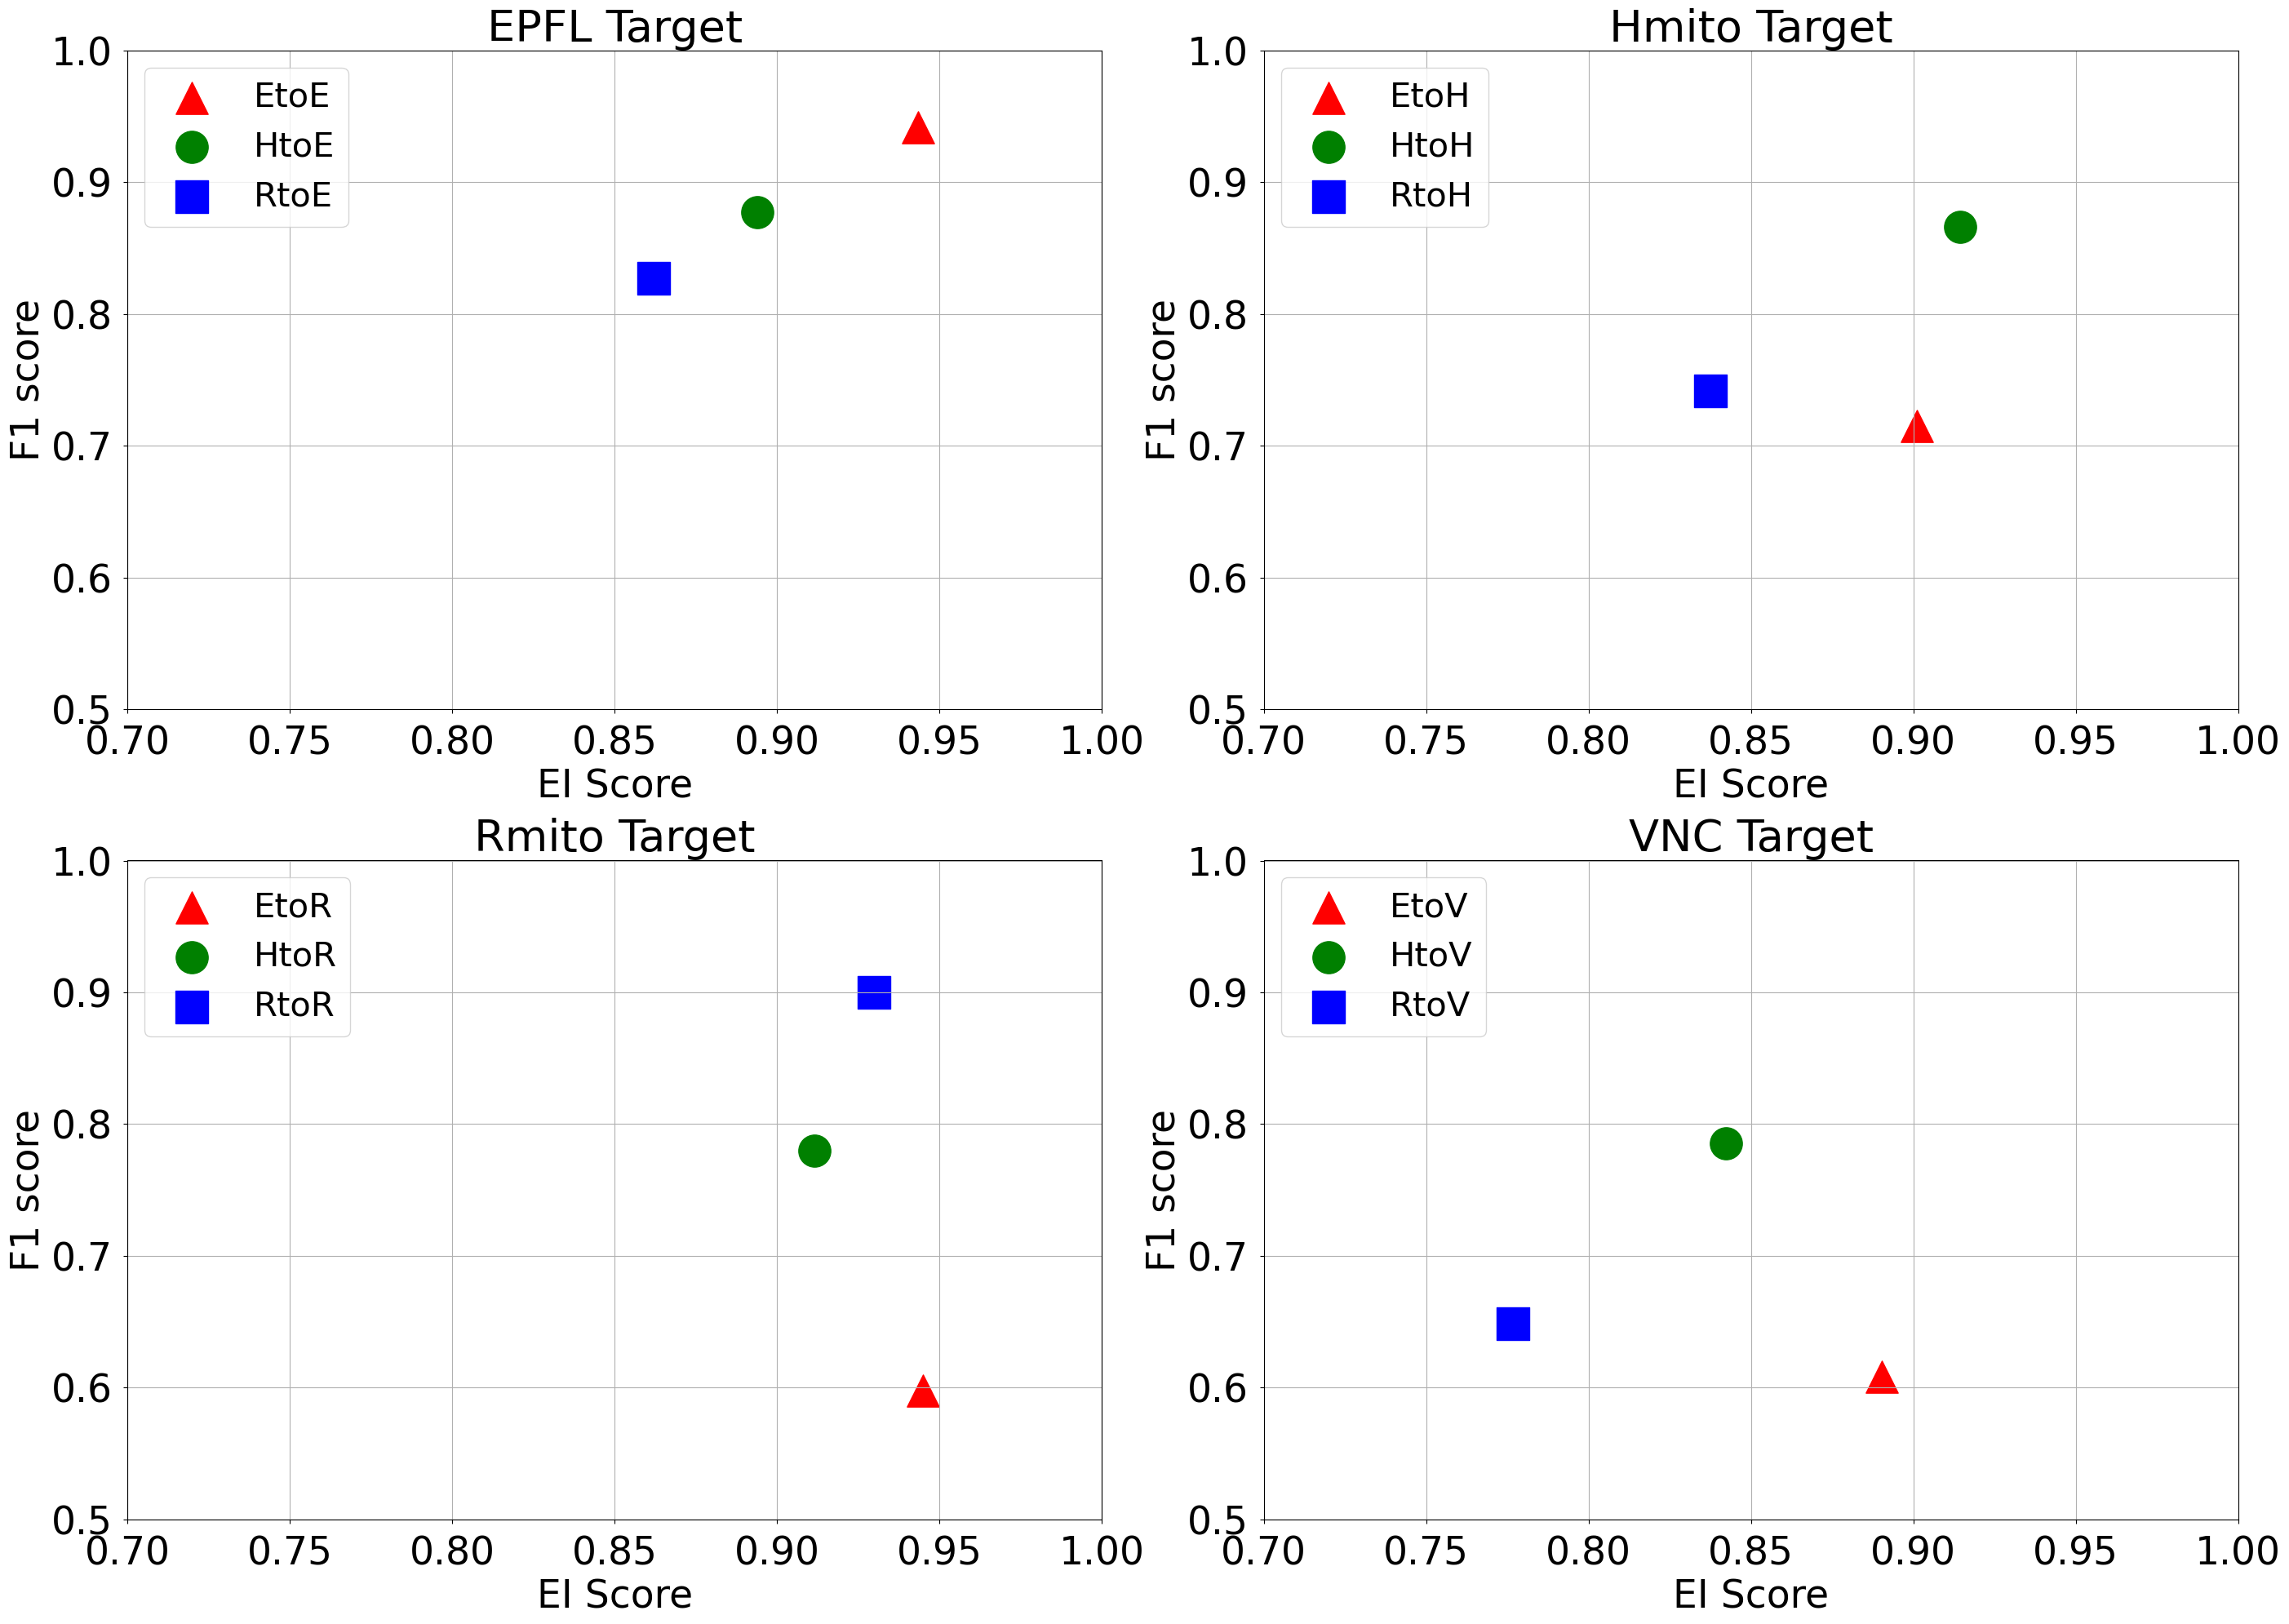

In [10]:
plot_combined_selected_augs_metric_vs_F1(
    EI_scores,
    F1_scores,
    "EI",
    target_datasets,
    source_datasets,
    augmentations,
    selected_alphas,
    xlim=(0.7, 1),
    ylim=(0.5, 1),
    figsize=(28, 20),
    point_size=800,
    fontsize=34,
    n_cols=2,
    n_rows=2,
    colors=["red", "green", "blue"],
    marker_by_source={"epfl": "^", "Hmito": "o", "Rmito": "s"},
    subplot_titles={
        "epfl": "EPFL Target",
        "Hmito": "Hmito Target",
        "Rmito": "Rmito Target",
        "VNC": "VNC Target",
    },
    x_label="EI Score",
    y_label="F1 score",
    save_path="/g/kreshuk/talks/model_ranking/notebooks/thesis/mitochondria/figures/classification/mito_EI_classification.svg",
)

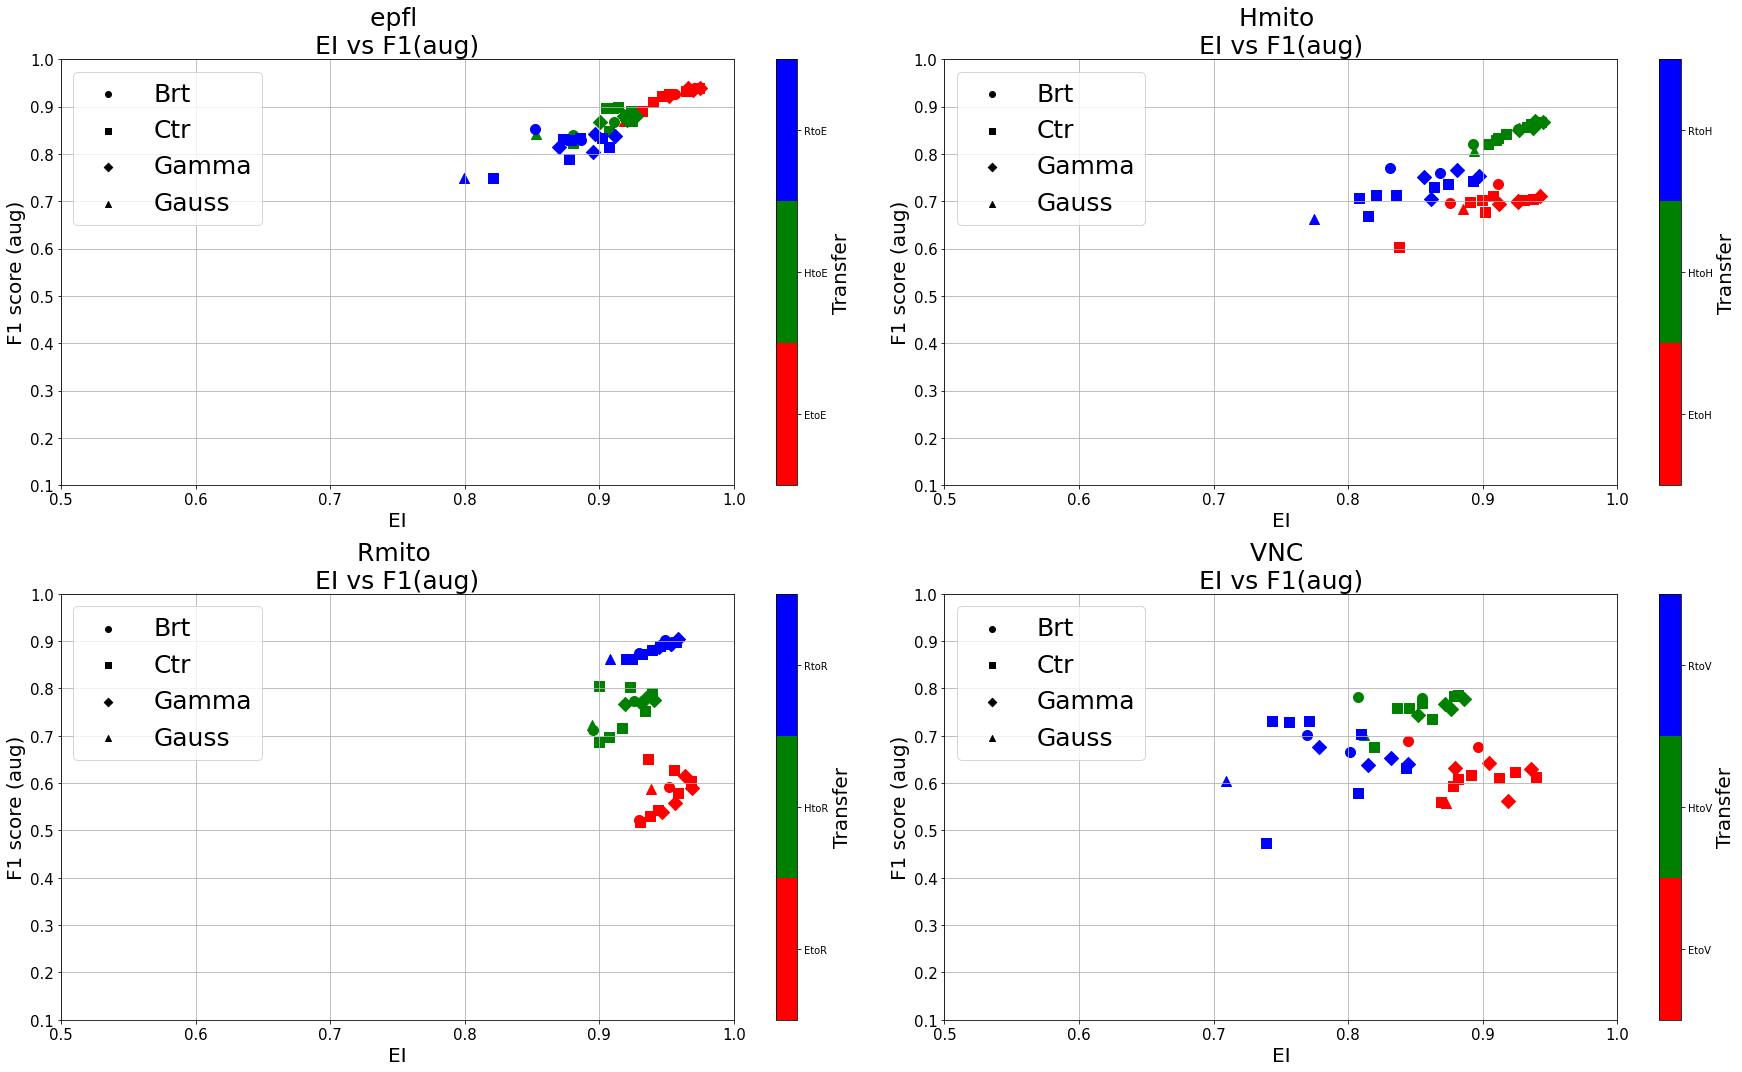

In [22]:
plot_metric_vs_F1_per_aug_for_aug_sweep(
    EI_scores,
    F1_scores,
    "EI",
    target_datasets,
    source_datasets,
    augmentations,
    selected_alphas3,
    xlim=(0.5, 1),
    ylim=(0.1, 1),
    figsize=(25, 15),
    point_size=100,
    fontsize=20,
    colors=["red", "green", "blue"],
    aug_markers=aug_markers,
)